In [60]:
%load_ext autoreload
%autoreload 1

In [1]:
import networkx as nx

from actors_graph import ActorsGraph

actors_graph = ActorsGraph("../resources/movie/data/casts.html")
actors_graph.build()
nx.write_gexf(actors_graph.g, "../results/actor_graph.gexf")

In [71]:
stats = actors_graph.stats()
print(stats)

{'nodes_count': 15849, 'edges_count': 144084, 'density': 0.0011472800042577494, 'clustering_coefficient': 0.7174012144318508, 'bridges': [('ray milland', 'claire griswold'), ('sophia loren', 'luca defillipo'), ('richard boone', 'joan vanark'), ('harvey keitel', 'zina bethune'), ('marcello mastroianni', 'anouk grinberg'), ('michael riley', 'stephen rappaport'), ('albert brooks', 'super dave osborne'), ('charles grodin', 'marlo thomas'), ('rip torn', 'kevin conway'), ('seymour hicks', 'ellaline teriss'), ('richard roundtree', 'ed kovens'), ('duke howard', 'burt brinckerhoff'), ('marshall thompson', 'marla landi'), ('ethan hawke', 'julie delpie'), ('robert deniro', 'lenny bruce'), ('emilio estevez', 'phil brock'), ('anouk aimee', 'ives montand'), ('claude noiller', 'valentine tessier'), ('jean gabin', 'josephine baker'), ('lyda bonelli', 'mario bonnard'), ('christopher dienstag', 'monica caldwell'), ('kim basinger', 'lisa croisette'), ('michael douglas', 'marjorie griffiths'), ('glenn clo

## Bridges with degree higher than one 1

In [18]:
bridges = [
    (a, b) for (a, b) in stats["bridges"]
    if actors_graph.g.degree(a) > 1 and actors_graph.g.degree(b) > 1
]
bridges

[('giacomo rossistuart', 'vincent price'),
 ('karen black', 'michael emil'),
 ('chuck connors', 'rosel zech'),
 ('john hargreaves', 'bryan brown'),
 ('helmut berger', 'marisa mell'),
 ('john belushi', 'blair brown'),
 ('francisco rabal', 'silvia pinal')]

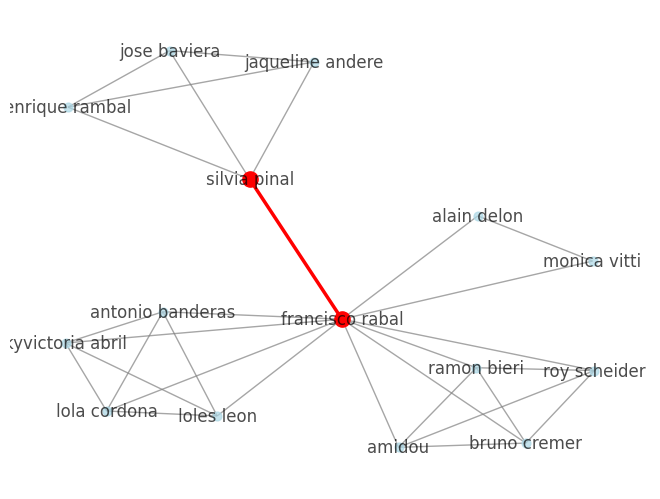

In [26]:
import networkx as nx
from matplotlib import pyplot as plt

u, v = ('francisco rabal', 'silvia pinal')
# nodes_u = nx.single_source_shortest_path_length(actors_graph.g, u, cutoff=2).keys()
nodes_u = nx.neighbors(actors_graph.g, u)
nodes_v = nx.neighbors(actors_graph.g, v)
# nodes_v = nx.single_source_shortest_path_length(actors_graph.g, v, cutoff=2).keys()
nodes = set(nodes_u) | set(nodes_v)

subG = actors_graph.g.subgraph(nodes).copy()
pos = nx.kamada_kawai_layout(subG)
scale = 3  # try 2–5
pos = {k: (x * scale, y * scale) for k, (x, y) in pos.items()}

# base graph
nx.draw(
    subG,
    pos,
    node_size=40,
    node_color="lightblue",
    edge_color="gray",
    with_labels=True,
    alpha=0.7
)

# highlight nodes
nx.draw_networkx_nodes(
    subG,
    pos,
    nodelist=[u, v],
    node_color="red",
    node_size=120
)

# highlight edge
nx.draw_networkx_edges(
    subG,
    pos,
    edgelist=[(u, v)],
    edge_color="red",
    width=2.5
)
plt.show()

## Local bridges with degree > 1

In [33]:
bridges = [
    (a, b) for (a, b, _) in stats["local_bridges"]
    if actors_graph.g.degree(a) > 1 and actors_graph.g.degree(b) > 1
]
bridges

[('alfie bass', 'david kosoff'),
 ('richard burton', 'tatum oneal'),
 ('rod taylor', 'betty lou gerson'),
 ('alan alda', 'ellen burstyn'),
 ('michael caine', 'glenda jackson'),
 ('michael caine', 'julie walters'),
 ('brooke adams', 'sean connery'),
 ('scott baio', 'jodie foster'),
 ('scott baio', 'willie aames'),
 ('vittorio desica', 'anna magnani'),
 ('harvey keitel', 'gian maria volonte'),
 ('faye dunaway', 'diana scarwid'),
 ('marcello mastroianni', 'catherine deneuve'),
 ('charles grodin', 'farrah fawcett'),
 ('sam waterston', 'susan blakely'),
 ('constance cummings', 'harold lloyd'),
 ('ann turkel', 'john vernon'),
 ('rod steiger', 'john beal'),
 ('john barrymore', 'diana wynyard'),
 ('anna may wong', 'sojin'),
 ('arthur hill', 'rod cameron'),
 ('paul hartman', 'robert webber'),
 ('joby baker', 'michael parks'),
 ('lola allbright', 'charles bronson'),
 ('charles bronson', 'linda cristal'),
 ('brian keith', 'joanna moore'),
 ('alan rickman', 'emma thompson'),
 ('gary oldman', 'ther

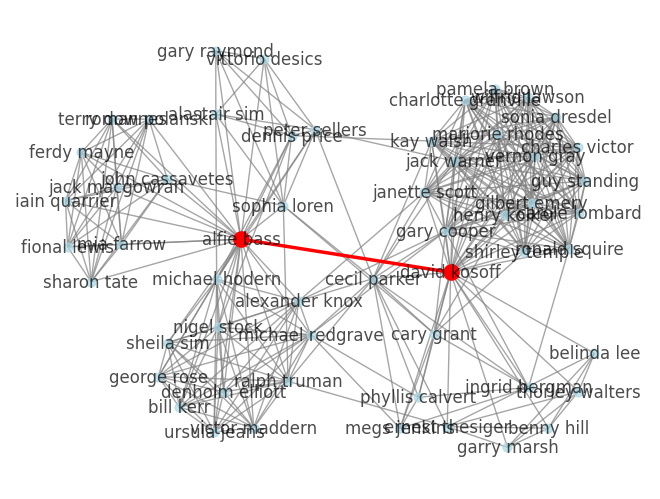

In [35]:
import networkx as nx
from matplotlib import pyplot as plt

u, v = ('alfie bass', 'david kosoff')
# nodes_u = nx.single_source_shortest_path_length(actors_graph.g, u, cutoff=2).keys()
nodes_u = nx.neighbors(actors_graph.g, u)
nodes_v = nx.neighbors(actors_graph.g, v)
# nodes_v = nx.single_source_shortest_path_length(actors_graph.g, v, cutoff=2).keys()
nodes = set(nodes_u) | set(nodes_v)

subG = actors_graph.g.subgraph(nodes).copy()
pos = nx.kamada_kawai_layout(subG)
scale = 3  # try 2–5
pos = {k: (x * scale, y * scale) for k, (x, y) in pos.items()}

# base graph
nx.draw(
    subG,
    pos,
    node_size=40,
    node_color="lightblue",
    edge_color="gray",
    with_labels=True,
    alpha=0.7
)

# highlight nodes
nx.draw_networkx_nodes(
    subG,
    pos,
    nodelist=[u, v],
    node_color="red",
    node_size=120
)

# highlight edge
nx.draw_networkx_edges(
    subG,
    pos,
    edgelist=[(u, v)],
    edge_color="red",
    width=2.5
)
plt.show()

## Degree distribution

0 413 1


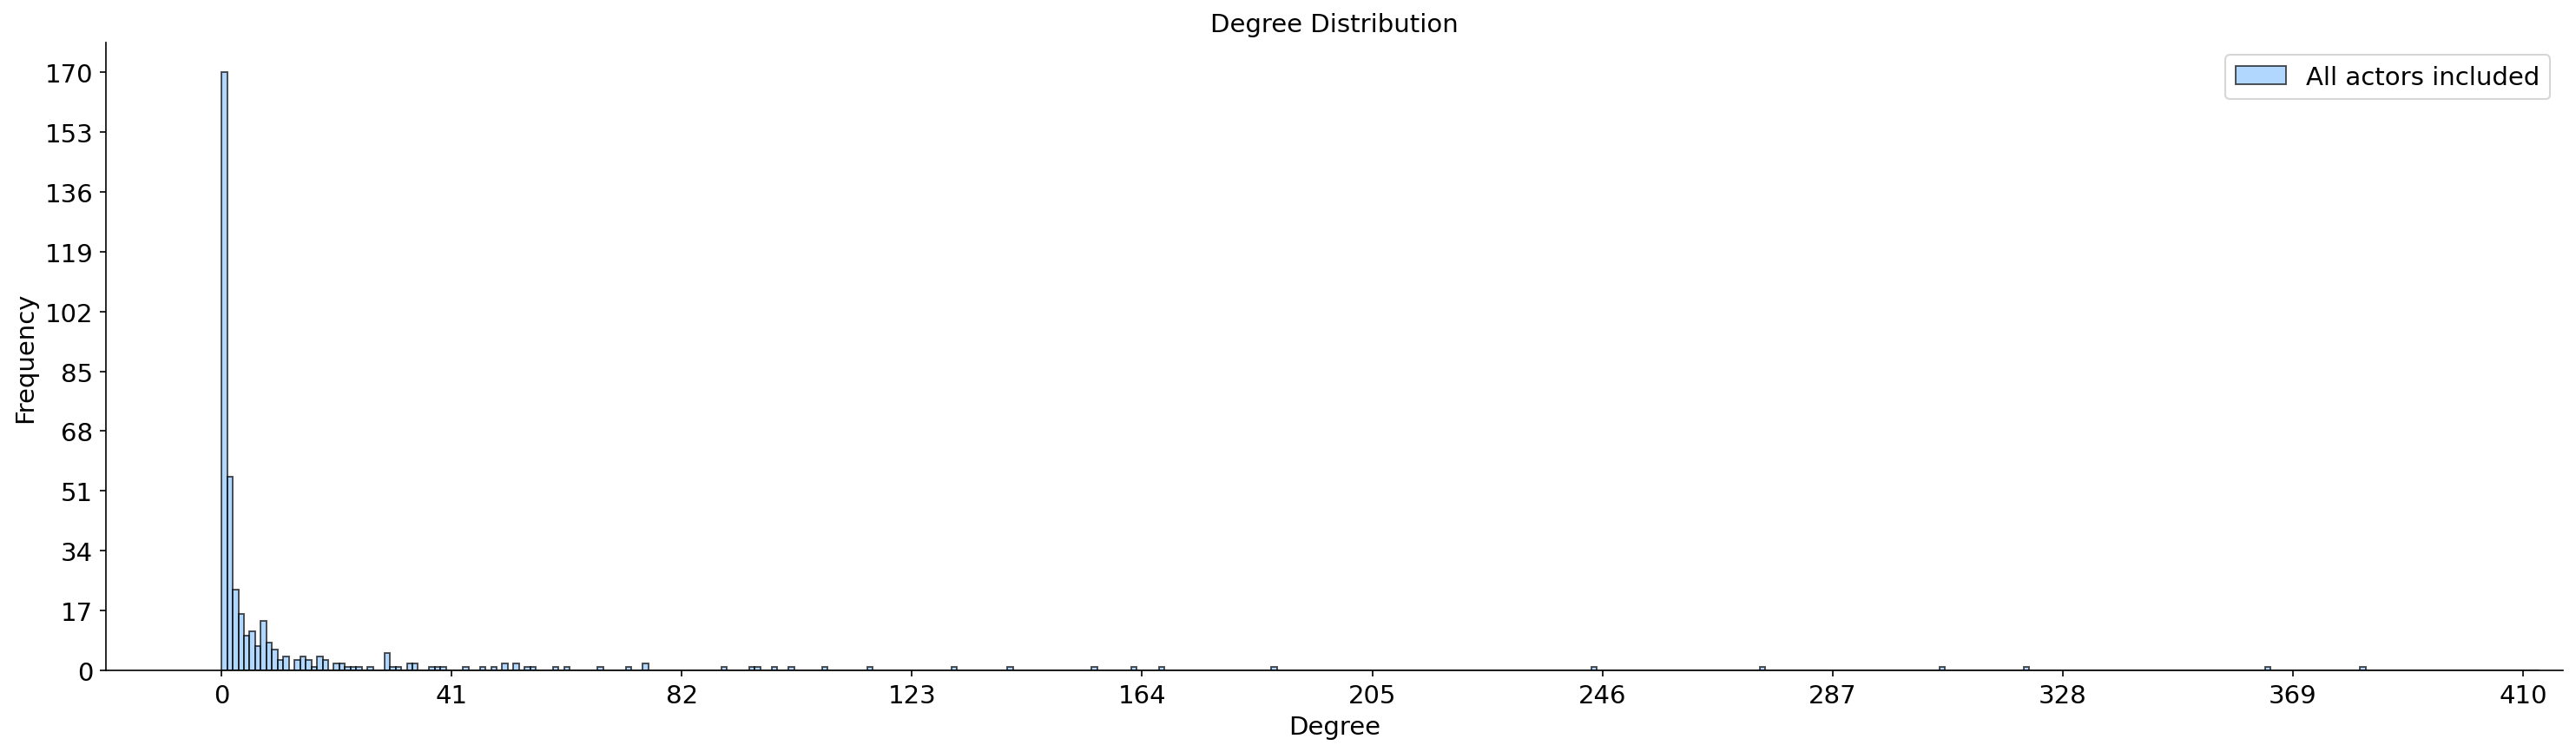

In [70]:
import importlib
import plotter

importlib.reload(plotter)

from plotter import Plotter

Plotter().plot_histogram_bin_count(
    sequence=stats["degree_histogram"],
    bins_count=len(stats["degree_histogram"]),
    log_y_scale=False,
    title="Degree Distribution",
    x_label="Degree",
    y_label="Frequency",
    label="All actors included",
)

In [ ]:
actors_graph.component_stats()

In [ ]:
nx.write_graphml(actors_graph.g, "../results/full-dataset.graphml")

In [ ]:
list(nx.selfloop_edges(actors_graph.g))

In [5]:
import re
REJECT_REGEX = re.compile(r"^s\s?a$", re.UNICODE)
print(REJECT_REGEX.match("sa"))
print(REJECT_REGEX.match("s a"))

<re.Match object; span=(0, 2), match='sa'>
<re.Match object; span=(0, 3), match='s a'>
